In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost torch shap streamlit jupyter ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

df = pd.read_csv("../Cleaned_Data/cleaned_ai4i2020.csv")

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

y = df["Machine failure"]

In [4]:
X = pd.get_dummies(X, columns=["Type"], drop_first=True)

X.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,True
1,298.2,308.7,1408,46.3,3,True,False
2,298.1,308.5,1498,49.4,5,True,False
3,298.2,308.6,1433,39.5,7,True,False
4,298.2,308.7,1408,40.0,9,True,False


In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 7)
y shape: (10000,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
print("Training set:")
print(y_train.value_counts())

print("\nTesting set:")
print(y_test.value_counts())

Training set:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing set:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nFirst training row:")
print(X_train_scaled[0])

Training shape: (8000, 7)
Testing shape: (2000, 7)

First training row:
[ 0.99891359  0.60428162 -0.46060741  0.71830476 -0.84399726 -1.23436595
  1.53620728]


In [10]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

In [11]:
y_pred_lr = lr_model.predict(X_test_scaled)

print(y_pred_lr[:20])

[1 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0]


In [12]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[1593  339]
 [  12   56]]


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [15]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.71      0.73        68

    accuracy                           0.98      2000
   macro avg       0.87      0.85      0.86      2000
weighted avg       0.98      0.98      0.98      2000



In [17]:
from sklearn.metrics import roc_auc_score

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.963867068566557


In [18]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

Torque [Nm]                0.322362
Rotational speed [rpm]     0.286201
Tool wear [min]            0.213284
Air temperature [K]        0.098706
Process temperature [K]    0.063921
Type_L                     0.009123
Type_M                     0.006403
dtype: float64


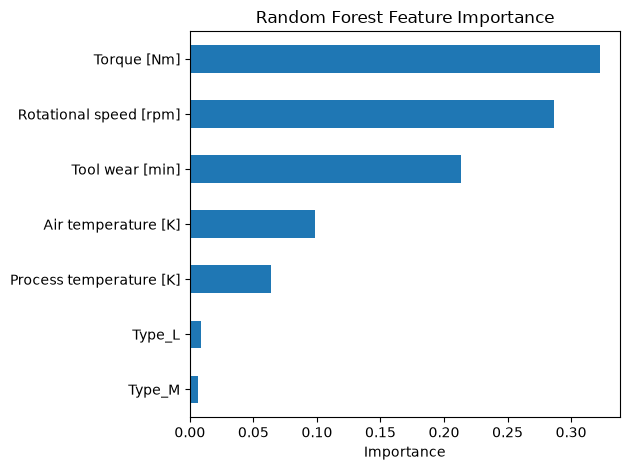

In [19]:
import matplotlib.pyplot as plt

feature_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [23]:
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb.columns = [
    "air_temp",
    "process_temp",
    "rotational_speed",
    "torque",
    "tool_wear",
    "type_L",
    "type_M"
]

X_test_xgb.columns = X_train_xgb.columns

In [24]:
xgb_model.fit(X_train_xgb, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [25]:
y_pred_xgb = xgb_model.predict(X_test_xgb)

print(y_pred_xgb[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.94      0.66      0.78        68

    accuracy                           0.99      2000
   macro avg       0.96      0.83      0.88      2000
weighted avg       0.99      0.99      0.99      2000



In [28]:
from sklearn.metrics import roc_auc_score

y_prob_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost ROC-AUC:", roc_auc_xgb)

XGBoost ROC-AUC: 0.973853671903544


In [29]:
import torch

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.values, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.values, dtype=torch.float32
).reshape(-1, 1)

In [31]:
import torch.nn as nn

class FailurePredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(7, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

model = FailurePredictor()

print(model)

FailurePredictor(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [32]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [33]:
for epoch in range(100):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train_tensor)

    loss = criterion(outputs, y_train_tensor)

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/100], Loss: {loss.item():.4f}")

Epoch [10/100], Loss: 0.5569
Epoch [20/100], Loss: 0.5326
Epoch [30/100], Loss: 0.5088
Epoch [40/100], Loss: 0.4839
Epoch [50/100], Loss: 0.4571
Epoch [60/100], Loss: 0.4285
Epoch [70/100], Loss: 0.3984
Epoch [80/100], Loss: 0.3674
Epoch [90/100], Loss: 0.3363
Epoch [100/100], Loss: 0.3061


In [34]:
model.eval()

with torch.no_grad():
    outputs = model(X_test_tensor)
    probabilities = torch.sigmoid(outputs)
    y_pred_dl = (probabilities >= 0.5).float()

print(y_pred_dl[:20])

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])


In [35]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_dl.numpy()
    )
)

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



d:\AI-Project\Predictive Maintenance\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI-Project\Predictive Maintenance\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI-Project\Predictive Maintenance\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

In [36]:
print("Predicted failures:", int(y_pred_dl.sum().item()))
print("Actual failures:", int(y_test_tensor.sum().item()))

Predicted failures: 0
Actual failures: 68


In [37]:
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Positive class weight:", positive_weight)

Positive class weight: 28.52029520295203


In [38]:
pos_weight = torch.tensor([positive_weight])

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

In [39]:
for epoch in range(100):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train_tensor)

    loss = criterion(outputs, y_train_tensor)

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/100], Loss: {loss.item():.4f}")

Epoch [10/100], Loss: 1.6773
Epoch [20/100], Loss: 1.5357
Epoch [30/100], Loss: 1.4179
Epoch [40/100], Loss: 1.3262
Epoch [50/100], Loss: 1.2570
Epoch [60/100], Loss: 1.2034
Epoch [70/100], Loss: 1.1598
Epoch [80/100], Loss: 1.1230
Epoch [90/100], Loss: 1.0912
Epoch [100/100], Loss: 1.0624


In [40]:
model.eval()

with torch.no_grad():
    outputs = model(X_test_tensor)
    probabilities = torch.sigmoid(outputs)
    y_pred_dl = (probabilities >= 0.5).float()

print("Predicted failures:", int(y_pred_dl.sum().item()))

Predicted failures: 561


In [41]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_dl.numpy(),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.99      0.74      0.85      1932
           1       0.10      0.84      0.18        68

    accuracy                           0.74      2000
   macro avg       0.55      0.79      0.51      2000
weighted avg       0.96      0.74      0.82      2000



In [42]:
from sklearn.metrics import roc_auc_score

roc_auc_dl = roc_auc_score(
    y_test,
    probabilities.numpy()
)

print("PyTorch ROC-AUC:", roc_auc_dl)

PyTorch ROC-AUC: 0.851867921081476


In [43]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "PyTorch Neural Network"
    ],
    "Failure Precision": [
        0.14,
        0.75,
        0.94,
        0.10
    ],
    "Failure Recall": [
        0.82,
        0.71,
        0.66,
        0.84
    ],
    "Failure F1": [
        0.24,
        0.73,
        0.78,
        0.18
    ],
    "ROC-AUC": [
        None,
        0.963867,
        0.973854,
        0.851868
    ]
})

results

,Model,Failure Precision,Failure Recall,Failure F1,ROC-AUC
0,Logistic Regression,0.14,0.82,0.24,NaN
1,Random Forest,0.75,0.71,0.73,0.963867
2,XGBoost,0.94,0.66,0.78,0.973854
3,PyTorch Neural Network,0.10,0.84,0.18,0.851868


In [44]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[1916   16]
 [  20   48]]


In [45]:
id_fn = X_test.index[(y_test == 1) & (y_pred_rf == 0)]

print("Number of missed failures:", len(id_fn))
print("Indexes of missed failures:")
print(id_fn.tolist())

Number of missed failures: 20
Indexes of missed failures:
[4851, 4632, 7884, 9174, 3806, 2671, 926, 2864, 4307, 3695, 1833, 4720, 7087, 2941, 9015, 4778, 7849, 8506, 1996, 4034]


In [46]:
missed_failures = df.loc[id_fn]

missed_failures[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure"
    ]
]

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
4851,L,303.7,312.1,1363,51.8,90,1
4632,M,302.9,311.2,1330,53.7,200,1
7884,L,300.8,312.4,1465,59.1,91,1
9174,L,297.8,308.9,1871,25.6,200,1
3806,M,302.3,310.9,1360,44.0,67,1
2671,M,299.7,309.3,1399,41.9,221,1
926,L,295.6,306.1,1372,55.6,215,1
2864,H,300.6,309.4,1380,47.6,246,1
4307,L,301.4,309.9,1259,63.9,20,1
3695,L,302.2,311.3,1530,37.3,207,1


In [47]:
print(missed_failures["Type"].value_counts())

Type
L    11
M     7
H     2
Name: count, dtype: int64


In [48]:
id_fp = X_test.index[(y_test == 0) & (y_pred_rf == 1)]

print("Number of false alarms:", len(id_fp))
print("Indexes of false alarms:")
print(id_fp.tolist())

Number of false alarms: 16
Indexes of false alarms:
[4231, 6276, 5692, 5701, 3596, 3794, 7677, 7086, 3843, 6127, 5988, 3866, 5270, 8607, 6612, 4113]


In [49]:
false_alarms = df.loc[id_fp]

print(false_alarms["Type"].value_counts())

Type
L    12
M     3
H     1
Name: count, dtype: int64


In [50]:
import shap

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test)

print("SHAP values calculated.")

SHAP values calculated.


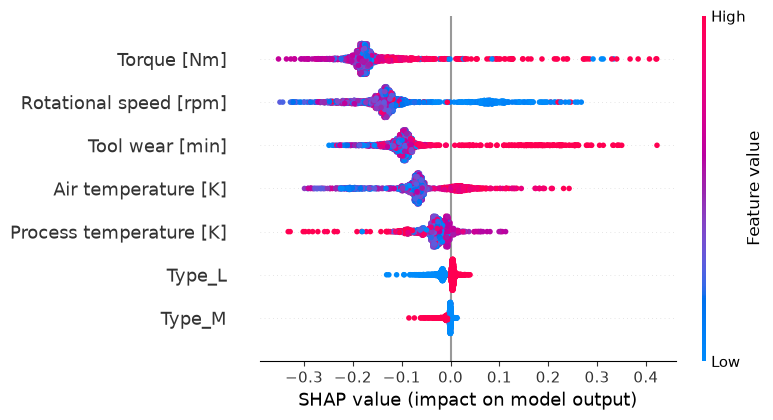

In [51]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    feature_names=X.columns
)

In [52]:
shap_importance = pd.Series(
    abs(shap_values[:, :, 1]).mean(axis=0),
    index=X.columns
).sort_values(ascending=False)

print(shap_importance)

Torque [Nm]                0.167672
Rotational speed [rpm]     0.138786
Tool wear [min]            0.107570
Air temperature [K]        0.073586
Process temperature [K]    0.032673
Type_L                     0.012650
Type_M                     0.004663
dtype: float64


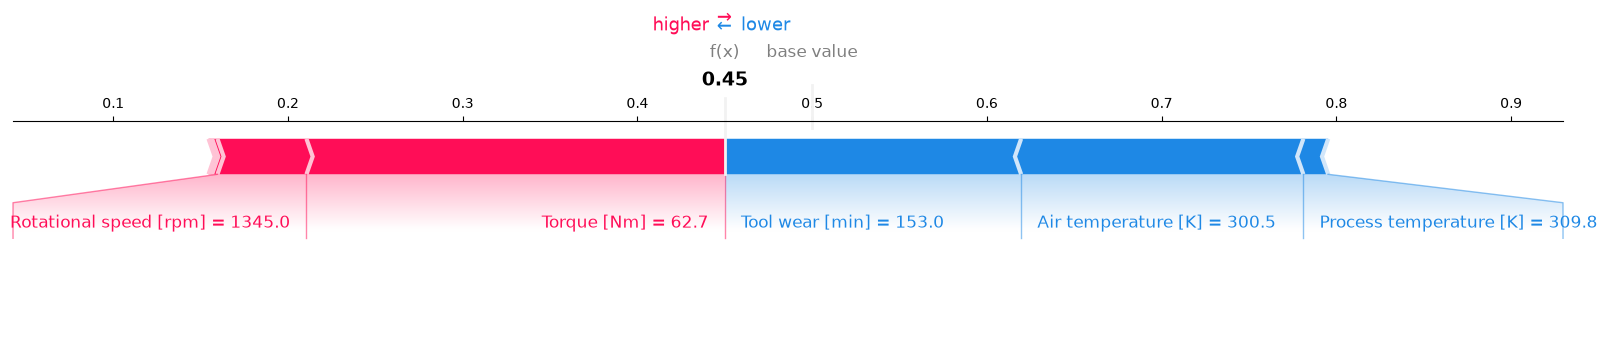

In [53]:
shap.force_plot(
    explainer.expected_value[1],
    shap_values[0, :, 1],
    X_test.iloc[0],
    matplotlib=True
)

In [54]:
risk_probability = y_prob_xgb

print("First 10 failure probabilities:")
print(risk_probability[:10])

First 10 failure probabilities:
[0.15181191 0.00115751 0.04605675 0.00139468 0.03615426 0.00112237
 0.02656963 0.00098375 0.00026799 0.05280442]


In [55]:
def get_risk_level(probability):
    if probability < 0.10:
        return "Low"
    elif probability < 0.30:
        return "Medium"
    else:
        return "High"


risk_levels = [get_risk_level(p) for p in risk_probability]

print(risk_levels[:10])

['Medium', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low']


In [56]:
risk_distribution = pd.Series(risk_levels).value_counts()

print(risk_distribution)

Low       1876
High        69
Medium      55
Name: count, dtype: int64


In [57]:
prediction_results = X_test.copy()

prediction_results["Actual Failure"] = y_test
prediction_results["Failure Probability"] = risk_probability
prediction_results["Risk Level"] = risk_levels

prediction_results.head(10)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M,Actual Failure,Failure Probability,Risk Level
2997,300.5,309.8,1345,62.7,153,True,False,0,0.151812,Medium
4871,303.7,312.4,1513,40.1,135,True,False,0,0.001158,Low
3858,302.5,311.4,1559,37.6,209,True,False,0,0.046057,Low
951,295.6,306.3,1509,35.8,60,False,False,0,0.001395,Low
6463,300.5,310.0,1358,60.4,102,False,False,0,0.036154,Low
3264,301.3,310.1,1455,44.1,188,False,False,0,0.001122,Low
4508,302.4,310.0,1426,46.6,102,True,False,0,0.026570,Low
2100,299.3,309.3,1471,46.0,42,False,True,0,0.000984,Low
7885,300.7,312.3,1590,36.3,93,True,False,0,0.000268,Low
2421,298.9,308.2,2384,15.0,19,True,False,0,0.052804,Low


In [58]:
import joblib

joblib.dump(xgb_model, "../xgb_model.pkl")

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


In [59]:
joblib.dump(scaler, "../scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


In [60]:
joblib.dump(scaler, "../scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


In [61]:
import os

print("XGBoost model exists:", os.path.exists("../xgb_model.pkl"))
print("Scaler exists:", os.path.exists("../scaler.pkl"))

XGBoost model exists: True
Scaler exists: True
